# Assignment 1 — Data Exploration and Cleaning: Users

We examine `users.xml`, clean verified data quality issues, and enrich users with information from posts, follow relationships, and the supplied event sample.

The original file is preserved. The main output keeps its nine columns; derived features and unresolved issues are exported separately.

**Requirements:** Python 3.10+, pandas 2.0+, NumPy, and Matplotlib. Run the cells in order. Only `DATA_DIR` needs to be adjusted when sharing the notebook.


## 1. Load and inspect the XML

Each `<row>` describes a user. We read the XML once, check its field structure, and initially preserve values as strings.


In [38]:
from pathlib import Path
from collections import Counter
import xml.etree.ElementTree as ET

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("../../ProjectData")
OUTPUT_DIR = Path.cwd() / "output_users"
USERS_PATH = DATA_DIR / "users.xml"

records = []
structures = Counter()
context = ET.iterparse(USERS_PATH, events=("start", "end"))
_, root = next(context)

for event, elem in context:
    if event == "end" and elem.tag == "row":
        structures[tuple(child.tag for child in elem)] += 1
        records.append({child.tag: child.text for child in elem})
        root.clear()

df_raw = pd.DataFrame(records, dtype="string")
del records, context, root, elem

print("Rows and columns:", df_raw.shape)
print("XML field structures:", len(structures))
display(pd.Series(structures.values(), index=[str(s) for s in structures], name="Rows"))
display(df_raw.head())


Rows and columns: (487292, 9)
XML field structures: 1


('id_user', 'timestamp_user_creation', 'username', 'follower_count', 'following_count', 'profile_url', 'finished_follower_scrape', 'finished_following_scrape', 'finished_truth_scrape')    487292
Name: Rows, dtype: int64

,id_user,timestamp_user_creation,username,follower_count,following_count,profile_url,finished_follower_scrape,finished_following_scrape,finished_truth_scrape
0,1238,2022-02-01 00:00:00,jeffgolfs,886,204,https://truthsocial.com/@jeffgolfs,f,f,f
1,50,2022-02-01 00:00:00,MizW,2365,2929,https://truthsocial.com/@MizW,f,f,f
2,6951,2022-02-01 00:00:00,SusanCreech,870,1232,https://truthsocial.com/@SusanCreech,f,f,f
3,9861,2022-02-01 00:00:00,BMF6FeeTDeeP,1086,1654,https://truthsocial.com/@BMF6FeeTDeeP,f,f,f
4,34,2022-02-01 00:00:00,DC_Draino,286146,81,https://truthsocial.com/@DC_Draino,t,t,t


In [4]:
count_cols = ["follower_count", "following_count"]
flag_cols = [
    "finished_follower_scrape",
    "finished_following_scrape",
    "finished_truth_scrape"
]
profile_cols = ["timestamp_user_creation"] + count_cols + flag_cols
original_columns = df_raw.columns.tolist()
expected_columns = ["id_user", "timestamp_user_creation", "username"] + count_cols + ["profile_url"] + flag_cols
assert original_columns == expected_columns

baseline = pd.DataFrame({
    "Type": df_raw.dtypes.astype(str),
    "Null or blank": [df_raw[c].isna().sum() + df_raw[c].str.strip().eq("").sum() for c in df_raw],
    "Sentinel -1": [df_raw[c].str.strip().eq("-1").sum() for c in df_raw],
    "Distinct values": df_raw.nunique()
})
display(baseline)
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Repeated user IDs:", df_raw["id_user"].duplicated().sum())


,Type,Null or blank,Sentinel -1,Distinct values
id_user,string,0,0,487292
timestamp_user_creation,string,0,465337,16
username,string,0,18,487153
follower_count,string,0,465337,8695
following_count,string,0,465337,7313
profile_url,string,0,0,487150
finished_follower_scrape,string,0,465337,3
finished_following_scrape,string,0,465337,3
finished_truth_scrape,string,0,465337,3


Exact duplicate rows: 0
Repeated user IDs: 0


## 2. Missing values and data coverage

A value of `-1` means unavailable information in the profile fields and username. It must not be interpreted as zero, `False`, or a date.

We check whether the six profile fields are missing together. Statistics based on available profiles describe this subset, not necessarily all users.


In [6]:
sentinel = df_raw[profile_cols].eq("-1")
missing_patterns = sentinel.value_counts().reset_index(name="Users")
missing_patterns["Percentage"] = (missing_patterns["Users"] / len(df_raw) * 100).round(2)
display(missing_patterns)

profile_missing = sentinel.all(axis=1)
print("All six profile fields unavailable:", profile_missing.sum())
print("Partially unavailable:", (sentinel.any(axis=1) & ~profile_missing).sum())

coverage = pd.Series("available", index=df_raw.index, dtype="string")
coverage.loc[profile_missing] = "unavailable"
coverage.loc[sentinel.any(axis=1) & ~profile_missing] = "partial"
display(df_raw.groupby(coverage)["id_user"].count().rename("Users"))


,timestamp_user_creation,follower_count,following_count,finished_follower_scrape,finished_following_scrape,finished_truth_scrape,Users,Percentage
0,True,True,True,True,True,True,465337,95.49
1,False,False,False,False,False,False,21955,4.51


All six profile fields unavailable: 465337
Partially unavailable: 0


available       21955
unavailable    465337
Name: Users, dtype: int64

In [7]:
# Remove exact copies only; distinct user IDs are never merged by username.
df_clean = df_raw.drop_duplicates().copy()
removed_duplicates = len(df_raw) - len(df_clean)

for col in df_clean:
    df_clean[col] = df_clean[col].str.strip().replace("", pd.NA)
for col in profile_cols + ["username"]:
    df_clean[col] = df_clean[col].replace("-1", pd.NA)

numeric_issues = []
for col in ["id_user"] + count_cols:
    values = pd.to_numeric(df_clean[col], errors="coerce")
    invalid = df_clean[col].notna() & (values.isna() | values.mod(1).ne(0))
    numeric_issues.append({"Column": col, "Invalid numbers": int(invalid.sum())})
    assert not invalid.any(), f"Inspect invalid values in {col} before continuing."
    df_clean[col] = values.astype("Int64")

display(pd.DataFrame(numeric_issues))
assert df_clean["id_user"].notna().all()
assert df_clean["id_user"].gt(0).all()
assert df_clean["id_user"].is_unique

features = df_clean[["id_user"]].copy()
features["profile_coverage"] = coverage.loc[df_clean.index]
display(df_clean.isna().sum().to_frame("Missing after sentinel normalization"))


,Column,Invalid numbers
0,id_user,0
1,follower_count,0
2,following_count,0


,Missing after sentinel normalization
id_user,0
timestamp_user_creation,465337
username,18
follower_count,465337
following_count,465337
profile_url,0
finished_follower_scrape,465337
finished_following_scrape,465337
finished_truth_scrape,465337


## 3. Usernames and profile URLs

We compare usernames without changing their original capitalization. A repeated username is not a safe basis for merging user IDs.

The source associates missing usernames with `https://truthsocial.com/@nan`. These are placeholder URLs, not usable recovery evidence. Other username–URL conflicts are kept for review.


In [9]:
profile_pattern = r"(?i)^https?://(?:www\.)?truthsocial\.com/@([A-Za-z0-9_]+)/?$"
url_username = df_clean["profile_url"].str.extract(profile_pattern, expand=False)

# In this source, @nan paired with a missing username is a generated placeholder.
placeholder_url = df_clean["username"].isna() & url_username.str.lower().eq("nan").fillna(False)
df_clean.loc[placeholder_url, "profile_url"] = pd.NA
url_username = url_username.mask(placeholder_url)

recover_from_profile = df_clean["username"].isna() & url_username.notna()
df_clean.loc[recover_from_profile, "username"] = url_username[recover_from_profile]
features["username_recovery_source"] = "not_recovered"
features.loc[recover_from_profile, "username_recovery_source"] = "profile_url"

username_key = df_clean["username"].str.casefold()
profile_mismatch = (
    username_key.notna() & url_username.notna()
    & username_key.ne(url_username.str.casefold()).fillna(False)
)
invalid_profile = df_clean["profile_url"].notna() & url_username.isna()

features["profile_url_placeholder"] = placeholder_url
features["profile_url_invalid"] = invalid_profile
features["profile_url_mismatch"] = profile_mismatch

print("Placeholder profile URLs removed:", placeholder_url.sum())
print("Usernames recovered from profile URLs:", recover_from_profile.sum())
print("Other invalid URL formats:", invalid_profile.sum())
print("Username / URL conflicts:", profile_mismatch.sum())
display(df_clean.loc[profile_mismatch | invalid_profile, ["id_user", "username", "profile_url"]].head(10))


Placeholder profile URLs removed: 18
Usernames recovered from profile URLs: 0
Other invalid URL formats: 1
Username / URL conflicts: 3


,id_user,username,profile_url
6239,7804,WSJPolitics,https://truthsocial.com/@cpac
7040,6384,bean8920,https://truthsocial.com/@dani
7250,6582,SiydenGalanter,https://truthsocial.com/@lovelynn
445410,445480,please take the time to like and/or ReTruth th...,https://truthsocial.com/@please take the time ...


In [10]:
duplicate_username = username_key.notna() & username_key.duplicated(keep=False)
duplicate_profiles = df_clean["profile_url"].notna() & df_clean["profile_url"].duplicated(keep=False)
features["username_shared_by_multiple_ids"] = duplicate_username
features["profile_url_shared_by_multiple_ids"] = duplicate_profiles

repeated_names = df_clean.loc[duplicate_username].groupby(username_key[duplicate_username]).agg(
    users=("id_user", "nunique"),
    profile_urls=("profile_url", "nunique")
)
print("Repeated normalized usernames:", len(repeated_names))
print("Records involved:", duplicate_username.sum())
display(repeated_names.sort_values("users", ascending=False).head(10))

# Include missing values when comparing repeated records.
attribute_variation = df_clean.loc[duplicate_username].groupby(
    username_key[duplicate_username]
)[profile_cols + ["profile_url"]].nunique(dropna=False)
print("Repeated-name groups with differing attributes:", (attribute_variation > 1).any(axis=1).sum())


Repeated normalized usernames: 79
Records involved: 206


,users,profile_urls
username,,
tialou83,8,1
alliechi,8,1
elle1223,8,1
flamingconservative,6,1
echo12,6,1
donochoa,5,1
jimcrotty16,4,1
zzzz4u,4,1
irishalicious,4,1


Repeated-name groups with differing attributes: 5


## 4. Creation dates and temporal precision

Parseability does not establish accuracy. Dates before 2021 are a screening rule inherited from the exploratory analysis, not a verified account creation boundary. Suspicious values are flagged and preserved.

We examine day and time precision. If every date is the first day of a month at midnight, daily or hourly creation patterns cannot be inferred reliably.


In [12]:
creation_raw = df_clean["timestamp_user_creation"].copy()
creation = pd.to_datetime(creation_raw, format="ISO8601", errors="coerce")
invalid_date = creation_raw.notna() & creation.isna()
assert not invalid_date.any(), "Inspect unparseable creation dates before continuing."
df_clean["timestamp_user_creation"] = creation

reference_date = pd.Timestamp("2026-11-11")
suspicious_date = creation.lt("2021-01-01") | creation.gt(reference_date)
features["creation_date_suspicious"] = suspicious_date
features["creation_date_at_month_start"] = creation.dt.is_month_start & creation.notna()

print("Available dates:", creation.notna().sum())
print("Range:", creation.min(), "to", creation.max())
print("Dates on day 1:", creation.dt.day.eq(1).sum())
print("Dates at midnight:", creation.eq(creation.dt.normalize()).sum())
print("Suspicious dates preserved:", suspicious_date.sum())
display(df_clean.loc[suspicious_date, ["id_user", "username", "timestamp_user_creation"]])
display(creation.value_counts().sort_index().rename("Users"))


Available dates: 21955
Range: 1969-12-01 00:00:00 to 2022-12-01 00:00:00
Dates on day 1: 21955
Dates at midnight: 21955
Suspicious dates preserved: 2


,id_user,username,timestamp_user_creation
159,192,louderwithcrowder,1969-12-01
479,459,oldrowoutdoors,1969-12-01


timestamp_user_creation
1969-12-01        2
2021-09-01        5
2021-12-01        3
2022-01-01        6
2022-02-01    16262
2022-03-01     1494
2022-04-01     1048
2022-05-01     2211
2022-06-01      481
2022-07-01      181
2022-08-01      162
2022-09-01       59
2022-10-01       34
2022-11-01        6
2022-12-01        1
Name: Users, dtype: int64

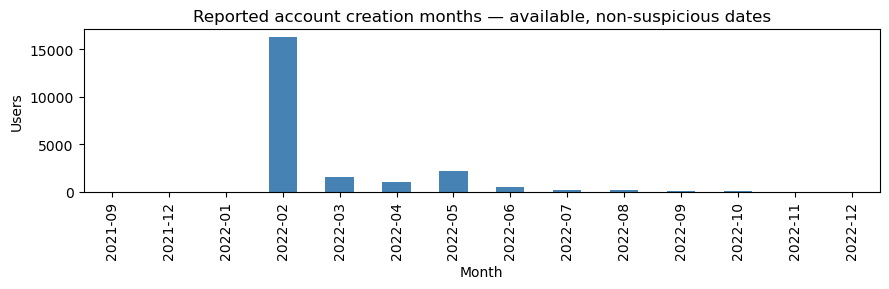

In [13]:
usable_creation = creation.where(~suspicious_date)
features["creation_year"] = usable_creation.dt.year.astype("Int64")
features["creation_month"] = usable_creation.dt.strftime("%Y-%m").astype("string")

monthly_creations = features["creation_month"].value_counts().sort_index()
monthly_creations.plot.bar(figsize=(9, 3), color="steelblue")
plt.title("Reported account creation months — available, non-suspicious dates")
plt.xlabel("Month")
plt.ylabel("Users")
plt.tight_layout()
plt.show()


## 5. Followers, following, and outliers

We examine only available, non-negative counts. Zero is a valid observed value. IQR outliers are inspected and retained: large counts alone do not establish an error or identify automated accounts.


In [15]:
assert not df_clean[count_cols].lt(0).any().any()
display(df_clean[count_cols].describe(percentiles=[.5, .9, .95, .99]).round(2))

outlier_rows = []
for col in count_cols:
    values = df_clean[col].dropna()
    q1, q3 = values.quantile([.25, .75])
    lower = q1 - 1.5 * (q3 - q1)
    upper = q3 + 1.5 * (q3 - q1)
    outliers = df_clean[col].lt(lower) | df_clean[col].gt(upper)
    features[col + "_iqr_outlier"] = outliers.astype("boolean")
    outlier_rows.append({
        "Metric": col, "Available users": len(values),
        "Zero counts": int(values.eq(0).sum()),
        "IQR lower": lower, "IQR upper": upper,
        "Outliers": int(outliers.sum()),
        "Outliers (%)": round(outliers.sum() / len(values) * 100, 2)
    })
display(pd.DataFrame(outlier_rows))

for col in count_cols:
    display(df_clean.nlargest(5, col)[["id_user", "username"] + count_cols])


,follower_count,following_count
count,21955.0,21955.0
mean,7311.81,3357.5
std,56325.8,5351.6
min,0.0,0.0
50%,1929.0,1540.0
90%,9598.6,7485.0
95%,17830.2,9381.6
99%,68801.32,25341.4
max,4027829.0,99514.0


,Metric,Available users,Zero counts,IQR lower,IQR upper,Outliers,Outliers (%)
0,follower_count,21955,587,-6674.25,12227.75,1656,7.54
1,following_count,21955,963,-7708.50,13247.50,617,2.81


,id_user,username,follower_count,following_count
19118,27,realDonaldTrump,4027829,3
564,300,DonaldJTrumpJr,2524434,227
246,160,truthsocial,2375491,2
85,105,dbongino,1955706,249
175,211,BabylonBee,1809193,1


,id_user,username,follower_count,following_count
1012,922,Blondies,97618,99514
2164,2189,TheExecutioner,82661,88242
2695,2649,theworldupdater,78095,83756
9926,9037,cyberhunter,80400,82711
2167,2192,luvSB1,78695,80633


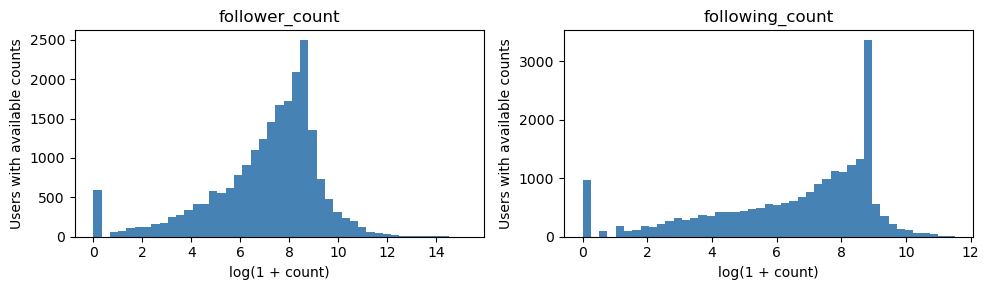

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, col in zip(axes, count_cols):
    values = df_clean[col].dropna().astype(float)
    ax.hist(np.log1p(values), bins=45, color="steelblue")
    ax.set_title(col)
    ax.set_xlabel("log(1 + count)")
    ax.set_ylabel("Users with available counts")
plt.tight_layout()
plt.show()

features["has_profile_counts"] = df_clean[count_cols].notna().all(axis=1)
features["followers_per_following"] = (
    df_clean["follower_count"] / df_clean["following_count"].where(df_clean["following_count"].gt(0))
).astype("Float64")


In [17]:
followers = df_clean["follower_count"].dropna().sort_values(ascending=False)
concentration = []
for percentage in [0.1, 1, 5, 10, 20]:
    n_users = max(1, int(np.ceil(len(followers) * percentage / 100)))
    concentration.append({
        "Top users (%)": percentage,
        "Users": n_users,
        "Share of reported follower counts (%)": round(followers.iloc[:n_users].sum() / followers.sum() * 100, 2)
    })
display(pd.DataFrame(concentration))


,Top users (%),Users,Share of reported follower counts (%)
0,0.1,22,19.24
1,1.0,220,43.83
2,5.0,1098,62.02
3,10.0,2196,70.69
4,20.0,4391,80.55


These concentration shares refer to the sum of available follower counts. They do not count distinct people, and they do not describe the users whose counts are unavailable.

## 6. Scraping completion

`t` and `f` become nullable booleans. Unknown status remains missing. These flags describe collection coverage, not whether an account is active.


In [19]:
display(pd.DataFrame({col: df_raw[col].value_counts(dropna=False) for col in flag_cols}))
for col in flag_cols:
    assert df_clean[col].dropna().isin(["t", "f"]).all()
    df_clean[col] = df_clean[col].map({"t": True, "f": False}).astype("boolean")
display(df_clean[flag_cols].value_counts(dropna=False).rename("Users").reset_index())


,finished_follower_scrape,finished_following_scrape,finished_truth_scrape
-1,465337,465337,465337
f,18240,18531,18724
t,3715,3424,3231


,finished_follower_scrape,finished_following_scrape,finished_truth_scrape,Users
0,<NA>,<NA>,<NA>,465337
1,False,False,False,18240
2,True,True,True,3231
3,True,False,False,291
4,True,True,False,193


## 7. Integration with follow relationships

We use `follows.json` to derive distinct observed in-degree and out-degree. Duplicate edges and self-follows are reported and excluded from these features only.

A zero observed degree means no such edge occurs in this file. It does not mean the account has no followers or follows nobody on the platform. Observed degrees never replace missing profile counts.


In [21]:
follows = pd.read_json(DATA_DIR / "follows.json")
follows = follows[["follower", "followed"]].copy()
for col in follows:
    values = pd.to_numeric(follows[col], errors="coerce")
    assert values.dropna().mod(1).eq(0).all()
    follows[col] = values.astype("Int64")

missing_edge = follows.isna().any(axis=1)
invalid_edge = follows.le(0).any(axis=1)
self_edge = follows["follower"].eq(follows["followed"]).fillna(False)
duplicate_edges = follows.duplicated().sum()
print("Relationships:", len(follows))
print("Missing endpoints:", missing_edge.sum())
print("Non-positive endpoints:", invalid_edge.sum())
print("Repeated edges:", duplicate_edges)
print("Self-follows:", self_edge.sum())

edges = follows.loc[~missing_edge & ~invalid_edge & ~self_edge].drop_duplicates().copy()
del follows
user_ids = pd.Index(df_clean["id_user"])
unknown_edge = ~edges["follower"].isin(user_ids) | ~edges["followed"].isin(user_ids)
unknown_network_ids = pd.Index(pd.concat([edges["follower"], edges["followed"]]).unique()).difference(user_ids)
print("Network IDs absent from users.xml:", unknown_network_ids.tolist())
print("Edges with at least one unknown user:", unknown_edge.sum())
display(edges.loc[unknown_edge].head(10))


Relationships: 4002115
Missing endpoints: 0
Non-positive endpoints: 0
Repeated edges: 99
Self-follows: 0
Network IDs absent from users.xml: [97]
Edges with at least one unknown user: 1


,follower,followed
1159076,26,97


In [22]:
observed_followers = edges.groupby("followed")["follower"].nunique()
observed_following = edges.groupby("follower")["followed"].nunique()
features["observed_follower_count"] = df_clean["id_user"].map(observed_followers).fillna(0).astype("Int64")
features["observed_following_count"] = df_clean["id_user"].map(observed_following).fillna(0).astype("Int64")
features["appears_in_follows"] = features[["observed_follower_count", "observed_following_count"]].gt(0).any(axis=1)

network_coverage = features.groupby("profile_coverage").agg(
    users=("id_user", "size"), in_network=("appears_in_follows", "sum")
)
network_coverage["Coverage (%)"] = (network_coverage["in_network"] / network_coverage["users"] * 100).round(2)
display(network_coverage)

network_comparison = []
for col in count_cols:
    known = df_clean[col].notna()
    difference = features.loc[known, "observed_" + col] - df_clean.loc[known, col]
    network_comparison.append({
        "Profile metric": col, "Comparable users": int(known.sum()),
        "Observed lower": int(difference.lt(0).sum()),
        "Equal": int(difference.eq(0).sum()),
        "Observed higher": int(difference.gt(0).sum())
    })
display(pd.DataFrame(network_comparison))
del edges


,users,in_network,Coverage (%)
profile_coverage,,,
available,21955,21801,99.3
unavailable,465337,423149,90.93


,Profile metric,Comparable users,Observed lower,Equal,Observed higher
0,follower_count,21955,21308,99,548
1,following_count,21955,19179,2251,525


Differences can arise from incomplete coverage, collection at different times, or source inconsistencies. We cannot choose a correct platform-wide count from these differences alone.

## 8. Posts: references and username recovery

We use the original `truths.csv` for independent recovery evidence. Reconstructed URLs from the Truths cleaning are not used to validate the same user information that produced them.

Post IDs associated with multiple numeric authors are excluded from this reference analysis. Missing usernames are recovered only when an author has one usable URL username and that name is not assigned to another known user ID.


In [25]:
posts = pd.read_csv(
    DATA_DIR / "truths.csv",
    usecols=["id", "author", "url", "timestamp"],
    dtype="string", keep_default_na=False
).drop_duplicates()

for col in ["id", "author"]:
    text = posts[col].str.strip().str.replace(r"\.0+$", "", regex=True)
    invalid = text.ne("") & ~text.str.fullmatch(r"\d+", na=False)
    assert not invalid.any(), f"Inspect invalid post {col} values."
    posts[col] = pd.to_numeric(text.replace("", pd.NA), errors="raise").astype("Int64")

missing_post_author = posts["author"].isna().sum()
author_variation = posts.groupby("id")["author"].nunique()
conflicting_post_ids = author_variation[author_variation > 1].index
print("Missing authors in distinct reference rows:", missing_post_author)
print("Conflicting post IDs excluded:", len(conflicting_post_ids))
posts = posts.loc[~posts["id"].isin(conflicting_post_ids) & posts["author"].gt(0).fillna(False)].copy()

unmatched_posts = posts.loc[~posts["author"].isin(user_ids)]
print("Distinct post IDs with absent authors:", unmatched_posts["id"].nunique())
display(unmatched_posts.groupby("author")["id"].nunique().rename("Distinct posts").to_frame())

posts["url_username"] = posts["url"].str.extract(
    r"(?i)^https?://(?:www\.)?truthsocial\.com/@([A-Za-z0-9_]+)/posts/\d+/?$", expand=False
).str.casefold()
posts["url_username"] = posts["url_username"].mask(posts["url_username"].isin(["nan", "none", "null"]))
candidate_counts = posts.groupby("author")["url_username"].nunique()
candidates = posts.loc[posts["author"].isin(candidate_counts[candidate_counts == 1].index)].groupby("author")["url_username"].first()

known_owners = pd.DataFrame({"name": username_key, "id_user": df_clean["id_user"]}).dropna()
candidate = df_clean["id_user"].map(candidates)
name_already_used = candidate.isin(known_owners["name"])
recover_from_posts = df_clean["username"].isna() & candidate.notna() & ~name_already_used
df_clean.loc[recover_from_posts, "username"] = candidate[recover_from_posts]
features.loc[recover_from_posts, "username_recovery_source"] = "original_truth_url"

print("Missing users with posts:", df_clean.loc[df_clean["username"].isna(), "id_user"].isin(posts["author"]).sum())
print("Usernames recovered from original posts:", recover_from_posts.sum())
print("Remaining missing usernames:", df_clean["username"].isna().sum())


Missing authors in distinct reference rows: 145
Conflicting post IDs excluded: 0
Distinct post IDs with absent authors: 3979


,Distinct posts
author,
97,257
1173,397
6364,3258
7838,67


Missing users with posts: 0
Usernames recovered from original posts: 0
Remaining missing usernames: 18


In [27]:
# Rebuild only absent URLs, using known, unambiguous usernames.
username_key = df_clean["username"].str.casefold()
shared_name = username_key.notna() & username_key.duplicated(keep=False)
rebuild_profile = df_clean["profile_url"].isna() & df_clean["username"].notna() & ~shared_name
df_clean.loc[rebuild_profile, "profile_url"] = "https://truthsocial.com/@" + df_clean.loc[rebuild_profile, "username"]
features["profile_url_reconstructed"] = rebuild_profile
features["username_shared_by_multiple_ids"] = shared_name

posts["timestamp"] = pd.to_datetime(posts["timestamp"], format="ISO8601", errors="coerce")
post_summary = posts.groupby("author").agg(
    observed_post_count=("id", "nunique"),
    first_observed_post=("timestamp", "min"),
    last_observed_post=("timestamp", "max")
)
features = features.merge(post_summary, left_on="id_user", right_index=True, how="left", validate="one_to_one")
features["observed_post_count"] = features["observed_post_count"].fillna(0).astype("Int64")

# Compare against the month boundary; the exact creation day is uncertain.
features["post_before_reported_creation_month"] = (
    features["first_observed_post"].lt(usable_creation.dt.to_period("M").dt.to_timestamp())
)
print("Users with observed posts:", features["observed_post_count"].gt(0).sum())
print("Posts before the reported creation month:", features["post_before_reported_creation_month"].sum())
display(features.nlargest(5, "observed_post_count")[["id_user", "observed_post_count", "first_observed_post", "last_observed_post"]])
del posts


Users with observed posts: 18672
Posts before the reported creation month: 96


,id_user,observed_post_count,first_observed_post,last_observed_post
230677,230747,14178,2024-05-09 23:18:00,2024-09-02 18:53:00
71849,71919,11613,2024-05-19 23:54:00,2024-10-27 04:21:00
198823,198893,10025,2023-11-22 16:05:00,2024-10-29 16:16:00
14058,12967,8267,2022-02-22 18:08:00,2022-10-14 20:16:00
11707,11363,8246,2022-03-03 17:30:00,2022-10-14 23:32:00


Post counts describe this corpus after removing conflicting author assignments; they are not total lifetime activity. Missing authors in the original posts are not repaired in this Users notebook.

## 9. Event sample: user references

We use only `subsample_events.xml`, as required by Assignment 1. Distinct event IDs prevent exact repetitions from inflating activity counts. We count observed events of all types; they are not all posts.


In [29]:
event_users = Counter()
seen_events = set()
invalid_events = 0
repeated_event_ids = 0
context = ET.iterparse(DATA_DIR / "subsample_events.xml", events=("start", "end"))
_, root = next(context)

for event, elem in context:
    if event == "end" and elem.tag == "row":
        event_id = (elem.findtext("event_id") or "").strip()
        user_id = (elem.findtext("user_id") or "").strip()
        if not event_id.isdecimal() or not user_id.isdecimal() or int(user_id) <= 0:
            invalid_events += 1
        elif event_id in seen_events:
            repeated_event_ids += 1
        else:
            seen_events.add(event_id)
            event_users[int(user_id)] += 1
        root.clear()

absent_event_users = pd.Index(list(event_users)).difference(user_ids)
print("Distinct usable sample events:", sum(event_users.values()))
print("Repeated event IDs excluded from features:", repeated_event_ids)
print("Invalid identifiers:", invalid_events)
print("Sample user IDs absent from users.xml:", len(absent_event_users))
print("Events involving absent users:", sum(event_users[i] for i in absent_event_users))
display(pd.Series({i: event_users[i] for i in absent_event_users}, name="Sample events", dtype="int64").head(10))

features["observed_sample_event_count"] = df_clean["id_user"].map(event_users).fillna(0).astype("Int64")
del seen_events, context, root, elem


Distinct usable sample events: 609694
Repeated event IDs excluded from features: 0
Invalid identifiers: 106949
Sample user IDs absent from users.xml: 0
Events involving absent users: 0


Series([], Name: Sample events, dtype: int64)

## 10. Final validation and exports

Missing values remain where there is no reliable recovery evidence. We retain repeated usernames, conflicting profile links, and suspicious dates with explicit indicators. Statistical outliers are unchanged.

`users_clean.csv` keeps the original schema. `users_features.csv` contains the derived attributes, and `users_issues.csv` lists unresolved cases for review. All files link through `id_user`.


In [31]:
df_final = df_clean[original_columns].copy()
assert len(df_final) == len(df_raw) - removed_duplicates
assert df_final["id_user"].notna().all() and df_final["id_user"].is_unique
assert df_final.columns.tolist() == original_columns
assert not df_final[count_cols].lt(0).any().any()
assert features["id_user"].is_unique
assert features["id_user"].tolist() == df_final["id_user"].tolist()

# Original available counts must remain unchanged.
for col in count_cols:
    original = pd.to_numeric(df_raw.loc[df_final.index, col].replace("-1", pd.NA)).astype("Int64")
    assert df_final[col].equals(original)

quality_summary = pd.DataFrame({
    "Original sentinel -1": baseline["Sentinel -1"],
    "Final missing": df_final.isna().sum(),
    "Final missing (%)": (df_final.isna().mean() * 100).round(2)
})
display(quality_summary)

issues = df_final[["id_user", "username", "profile_url"]].copy()
issues["missing_username"] = df_final["username"].isna()
issues["missing_profile_url"] = df_final["profile_url"].isna()
issue_columns = [
    "username_shared_by_multiple_ids", "profile_url_shared_by_multiple_ids",
    "profile_url_invalid", "profile_url_mismatch", "creation_date_suspicious",
    "post_before_reported_creation_month"
]
issues[issue_columns] = features[issue_columns]
issue_flags = ["missing_username", "missing_profile_url"] + issue_columns
issues = issues.loc[issues[issue_flags].any(axis=1)]

print("Cleaned dataset:", df_final.shape)
print("Feature dataset:", features.shape)
display(issues[issue_flags].sum().to_frame("Flagged users"))


,Original sentinel -1,Final missing,Final missing (%)
id_user,0,0,0.00
timestamp_user_creation,465337,465337,95.49
username,18,18,0.00
follower_count,465337,465337,95.49
following_count,465337,465337,95.49
profile_url,0,18,0.00
finished_follower_scrape,465337,465337,95.49
finished_following_scrape,465337,465337,95.49
finished_truth_scrape,465337,465337,95.49


Cleaned dataset: (487292, 9)
Feature dataset: (487292, 25)


,Flagged users
missing_username,18
missing_profile_url,18
username_shared_by_multiple_ids,206
profile_url_shared_by_multiple_ids,202
profile_url_invalid,1
profile_url_mismatch,3
creation_date_suspicious,2
post_before_reported_creation_month,96


In [32]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
df_final.to_csv(OUTPUT_DIR / "users_clean.csv", index=False)
features.to_csv(OUTPUT_DIR / "users_features.csv", index=False)
issues.to_csv(OUTPUT_DIR / "users_issues.csv", index=False)
quality_summary.to_csv(OUTPUT_DIR / "users_quality_summary.csv", index_label="Column")

# Confirm that CSV identifiers survive export without precision loss.
checked_rows = 0
for chunk in pd.read_csv(OUTPUT_DIR / "users_clean.csv", usecols=["id_user"], dtype={"id_user": "Int64"}, chunksize=50000):
    expected = df_final["id_user"].iloc[checked_rows:checked_rows + len(chunk)]
    assert chunk["id_user"].tolist() == expected.tolist()
    checked_rows += len(chunk)
assert checked_rows == len(df_final)
print("Exported to:", OUTPUT_DIR.resolve())


Exported to: /Users/alespinello/Desktop/Truth-Social-Analysis-and-Data-Warehousing---Decision-Support-Systems-/01_assignment/output_users


## 11. Conclusions and scope

**Observed results:** 487,292 users retained; 465,337 users without follower counts; 18 unresolved usernames; 3 username–URL conflicts; 1 malformed profile URL; 2 suspicious creation dates; 96 users with posts before the reported creation month.

- Most users lack profile metadata. Filling these fields with means, zero counts, or sampled network degrees would introduce unsupported information.
- `id_user` is the join key. Repeated usernames and profile links remain separate records because their IDs can be referenced elsewhere.
- Creation timestamps have limited precision. Suspicious dates are preserved for traceability and excluded from creation-month features.
- Profile counts, observed network degrees, corpus post counts, and sampled event counts describe different measurements and collection coverage.
- The useful text here is the username and its relationship to profile and post URLs. This file contains no biography or location field; we do not infer location, age, or political affiliation from account names. No external web data is needed for the supported corrections.

**Assignment 1 coverage:** structure and types (1), missing values (2), duplicates and consistency (3), temporal anomalies (4), outliers (5), collection coverage (6), integration and derived information (7–9), validated cleaning and exports (10).

This notebook completes the Users component. The required ARFF integration belongs to the main post corpus and must be completed in the Truths/Additional Truths notebook. Full event cleaning and the remaining datasets are separate components of Assignment 1.

**Sources:** the supplied `users.xml`, `truths.csv`, `follows.json`, and `subsample_events.xml`; the Assignment 1 instructions; and the original `01_02_explore_users.ipynb` and `01_11_clean_users.ipynb`. The cells consolidate those analyses and avoid their repeated or reverted recovery steps.
